# Oulu snow analysis: a reproducible opportunity assessment

**Question:** Do observed snow conditions justify investigating residential snow-clearing services in Oulu?

This portfolio edition extends the original DABI assignment. It uses the same FMI snapshot and distinguishes
snow cover, depth-change frequency and change magnitude. It does not forecast demand or estimate profitability.

**How to run:** install `requirements.txt`, open this notebook from the repository root and run all cells.
The raw data is included. No personal Drive path or account is needed. Outputs are saved under `outputs/`.
The small functions in `snow_analysis.py` handle validation and calculations; `snow_charts.py` contains plotting code.
Open those files to see or change the underlying calculations. The notebook follows each step explicitly.

**Source:** Finnish Meteorological Institute, Oulu Kaukovainio. The filename's requested period was 2016–2026,
but actual data starts 9 November 2023. This is **not a ten-year dataset**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from snow_analysis import (
    find_project_root, WEATHER_COLUMNS, clean_observations, select_window,
    summarize, coverage_audit, threshold_sensitivity, increase_magnitudes, export_tables,
)
from snow_charts import (
    plot_daily, plot_monthly, plot_common, plot_sensitivity,
    plot_magnitudes, export_interactive,
)
get_ipython().run_line_magic("matplotlib", "inline")
PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data/raw/oulu_kaukovainio_daily.xlsx"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

## 1. Read and validate the original observations

Keep the raw workbook unchanged. Validate the required columns, calendar dates, single station, duplicate dates,
numeric fields and invalid negative measurements before analysis. Unexpected text raises an error rather than
silently becoming missing data. Negative temperatures remain valid.

FMI defines daily snow `-1` as no snow, and snow `0` as no snow at the station but snow nearby.
Daily precipitation `-1` is no precipitation and `0` is a trace below 0.1 mm. New numerical columns convert
only these `-1` codes to zero. Trace precipitation is approximated as zero. Original weather columns retain
the sentinel values; `-` becomes missing in the cleaned copy.

[FMI field definitions](https://www.ilmatieteenlaitos.fi/neuvoja-havaintosuureisiin).

In [2]:
raw = pd.read_excel(DATA_PATH)
observations = clean_observations(raw)
print(f"Raw rows: {len(raw)}")
print(f"Actual date range: {observations['Date'].min():%Y-%m-%d} to {observations['Date'].max():%Y-%m-%d}")
print(f"All-weather-missing rows: {observations['All_weather_missing'].sum()}")
display(observations[WEATHER_COLUMNS].isna().sum().rename("Missing measurements"))
display(observations.loc[observations["All_weather_missing"], ["Date", *WEATHER_COLUMNS]])

Raw rows: 904
Actual date range: 2023-11-09 to 2026-04-30
All-weather-missing rows: 1


Snow depth [cm]              1
Average temperature [°C]     1
Precipitation amount [mm]    1
Maximum temperature [°C]     1
Minimum temperature [°C]     1
Name: Missing measurements, dtype: int64

,Date,Snow depth [cm],Average temperature [°C],Precipitation amount [mm],Maximum temperature [°C],Minimum temperature [°C]
0,2023-11-09,NaN,NaN,NaN,NaN,NaN


## 2. Audit coverage against the full winter calendar

A missing row, a present row with a missing reading, and a valid zero reading are different.
For every winter month, compare the input with all expected calendar dates. A complete winter here means
the **October–April study window**, not the meteorological definition of winter.

The first season lacks early dates. Do not infer that its missing October had zero snow.

In [3]:
monthly_coverage = coverage_audit(observations)
coverage = monthly_coverage.groupby("Winter")[[
    "Expected_days", "Rows_present", "Absent_dates", "Missing_snow_rows", "Valid_snow_days"
]].sum()
coverage["Coverage_pct"] = 100 * coverage["Valid_snow_days"] / coverage["Expected_days"]
coverage["Complete_window"] = coverage["Valid_snow_days"].eq(coverage["Expected_days"])
display(coverage.round(1))
display(monthly_coverage.round(1))

,Expected_days,Rows_present,Absent_dates,Missing_snow_rows,Valid_snow_days,Coverage_pct,Complete_window
Winter,,,,,,,
2023-2024,213,174,39,1,173,81.2,False
2024-2025,212,212,0,0,212,100.0,True
2025-2026,212,212,0,0,212,100.0,True


,Winter,Month,Expected_days,Rows_present,Absent_dates,Missing_snow_rows,Valid_snow_days,Coverage_pct
0,2023-2024,10,31,0,31,0,0,0.0
1,2023-2024,11,30,22,8,1,21,70.0
2,2023-2024,12,31,31,0,0,31,100.0
3,2023-2024,1,31,31,0,0,31,100.0
4,2023-2024,2,29,29,0,0,29,100.0
5,2023-2024,3,31,31,0,0,31,100.0
6,2023-2024,4,30,30,0,0,30,100.0
7,2024-2025,10,31,31,0,0,31,100.0
8,2024-2025,11,30,30,0,0,30,100.0
9,2024-2025,12,31,31,0,0,31,100.0


## 3. Analyse all available October–April observations

Exclude only rows where every weather measurement is missing; retain partially missing rows.
Snow-covered means **snow depth ≥1 cm**, not snowfall. Daily changes require consecutive dates within the
same winter and valid measurements at both endpoints. The first comparison of every window stays missing.

Snow-cover percentages use valid snow readings. Increase percentages use valid daily comparisons.
If there are no valid comparisons, the percentage is missing—not zero.

In [4]:
winter = select_window(observations)
winter_summary = summarize(winter)
monthly_summary = summarize(winter, groups=("Winter", "Month"))
print(f"Usable winter rows: {len(winter)}")
display(winter_summary.round(1))
display(monthly_summary.round(1))

Usable winter rows: 597


,Rows,Valid_snow_days,Snow_covered_days,Mean_depth_cm,Median_depth_cm,Maximum_depth_cm,Valid_comparisons,Increase_days,Maximum_increase_cm,Snow_cover_pct,Increase_pct
Winter,,,,,,,,,,,
2023-2024,173,173,170,33.6,39.0,65.0,172,45,8.0,98.3,26.2
2024-2025,212,212,117,7.2,4.0,26.0,211,43,8.0,55.2,20.4
2025-2026,212,212,114,8.1,3.5,41.0,211,34,10.0,53.8,16.1


Rows  Valid_snow_days  Snow_covered_days  Mean_depth_cm  \
Winter    Month                                                            
2023-2024 1        31               31                 31           37.4   
          2        29               29                 29           53.3   
          3        31               31                 31           46.9   
          4        30               30                 27           26.9   
          11       21               21                 21            6.1   
          12       31               31                 31           23.0   
2024-2025 1        31               31                 31           11.9   
          2        28               28                 28           21.1   
          3        31               31                 30           11.6   
          4        30               30                  4            0.5   
          10       31               31                  0            0.0   
          11       30               30                  6            0.9   
          12       31               31                 18            5.1   
2025-2026 1        31               31                 31           10.1   
          2        28               28                 28           22.3   
          3        31               31                 20           17.2   
          4        30               30                  0            0.0   
          10       31               31                  0            0.0   
          11       30               30                 16            4.9   
          12       31               31                 19            3.0   

                 Median_depth_cm  Maximum_depth_cm  Valid_comparisons  \
Winter    Month                                                         
2023-2024 1                 39.0              45.0                 31   
          2                 53.0              65.0                 29   
          3                 47.0              50.0                 31   
          4                 20.5              58.0                 30   
          11                 3.0              14.0                 20   
          12                20.0              35.0                 31   
2024-2025 1                 11.0              21.0                 31   
          2                 24.0              26.0                 28   
          3                 13.0              17.0                 31   
          4                  0.0               8.0                 30   
          10                 0.0               0.0                 30   
          11                 0.0               8.0                 30   
          12                 4.0              14.0                 31   
2025-2026 1                  7.0              20.0                 31   
          2                 20.5              36.0                 28   
          3                 15.0              41.0                 31   
          4                  0.0               0.0                 30   
          10                 0.0               0.0                 30   
          11                 2.5              16.0                 30   
          12                 3.0              10.0                 31   

                 Increase_days  Maximum_increase_cm  Snow_cover_pct  \
Winter    Month                                                       
2023-2024 1                  8                  6.0           100.0   
          2                  8                  8.0           100.0   
          3                  6                  3.0           100.0   
          4                  4                  8.0            90.0   
          11                 8                  5.0           100.0   
          12                11                  8.0           100.0   
2024-2025 1                 12                  8.0           100.0   
          2                  6                  6.0           100.0   
          3                

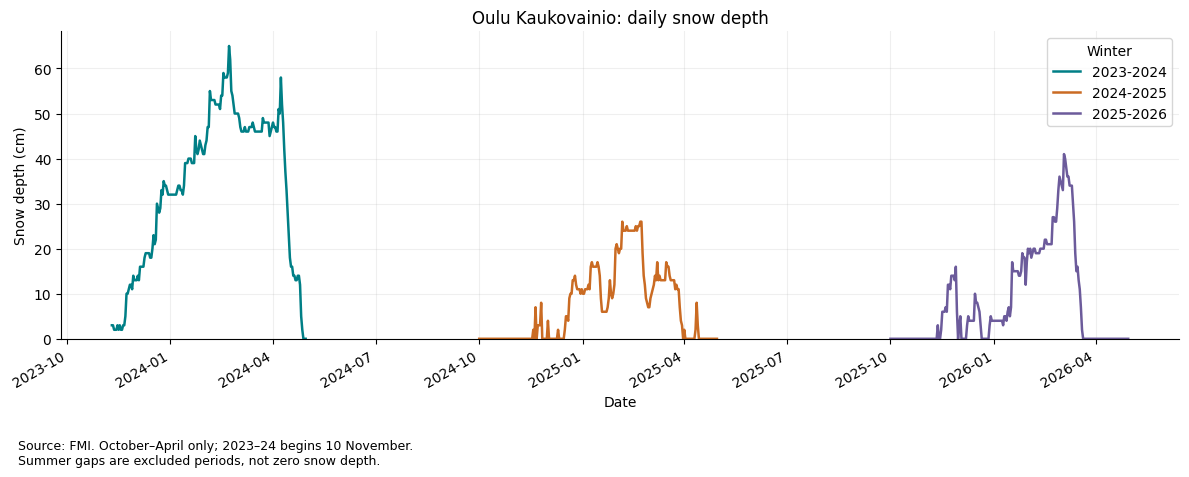

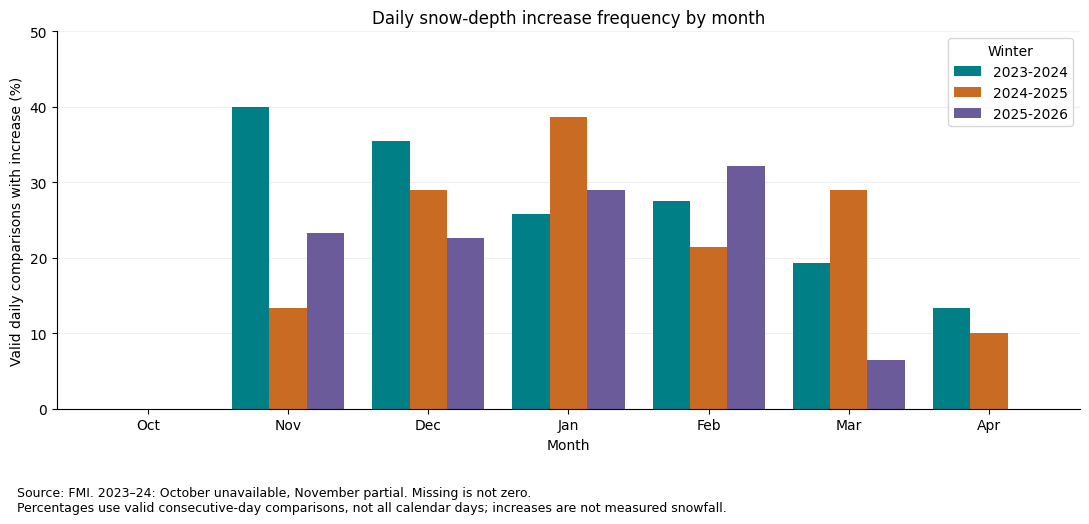

In [5]:
plot_daily(winter, FIGURE_DIR)
plot_monthly(monthly_summary, FIGURE_DIR)

## 4. Compare the same dates in every winter

The primary between-season comparison uses **10 November–30 April** in every winter, matching the first
available valid reading in 2023. Recompute differences within this window, excluding its first day.
Leap day is retained; percentages account for the different denominators (172 versus 171 comparisons).

This reduces coverage bias. It does not make three seasons representative of long-term climate.

,Rows,Valid_snow_days,Snow_covered_days,Mean_depth_cm,Median_depth_cm,Maximum_depth_cm,Valid_comparisons,Increase_days,Maximum_increase_cm,Snow_cover_pct,Increase_pct
Winter,,,,,,,,,,,
2023-2024,173,173,170,33.6,39.0,65.0,172,45,8.0,98.3,26.2
2024-2025,172,172,117,8.8,9.0,26.0,171,43,8.0,68.0,25.1
2025-2026,172,172,114,10.0,5.0,41.0,171,34,10.0,66.3,19.9


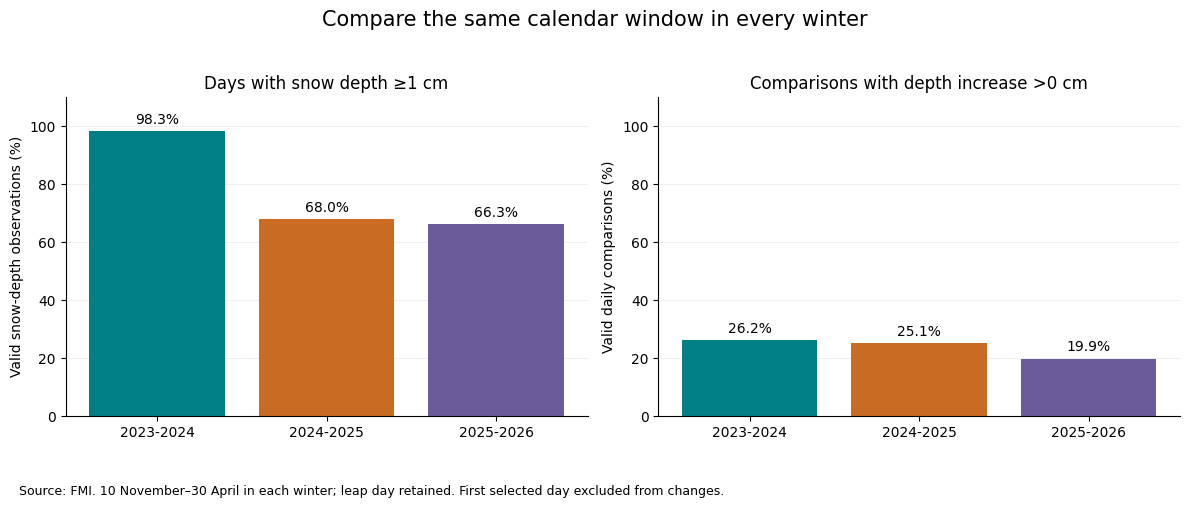

First two winters: available-window gap = 5.78 percentage points
First two winters: common-window gap = 1.02 percentage points


In [6]:
common = select_window(observations, start="11-10", end="04-30")
common_summary = summarize(common)
display(common_summary.round(1))
plot_common(common_summary, FIGURE_DIR)

gap_available = winter_summary.loc["2023-2024", "Increase_pct"] - winter_summary.loc["2024-2025", "Increase_pct"]
gap_common = common_summary.loc["2023-2024", "Increase_pct"] - common_summary.loc["2024-2025", "Increase_pct"]
print(f"First two winters: available-window gap = {gap_available:.2f} percentage points")
print(f"First two winters: common-window gap = {gap_common:.2f} percentage points")

**Interpretation:** The first two winters have similar increase frequencies once their dates are aligned,
despite very different snow-cover persistence. This is a stronger comparison than comparing the original
raw counts or percentages from unequal windows. Do not describe the three observations as a declining climate trend.

## 5. Sensitivity to the size of a depth increase

Compare increases of **at least 1, 3 and 5 cm**. These exploratory thresholds are not official clearing rules,
measurements of snowfall, or validated filters for measurement error. At least 1 cm matches >0 cm for the
integer-centimetre readings in this snapshot.

Use the common date window for the main chart. Export the available-window version separately so its
effect can be checked. A zero threshold would count unchanged days, so it is not allowed.

,Winter,Threshold_cm,Valid_comparisons,Days,Percent
0,2023-2024,1,172,45,26.2
1,2023-2024,3,172,17,9.9
2,2023-2024,5,172,9,5.2
3,2024-2025,1,171,43,25.1
4,2024-2025,3,171,14,8.2
5,2024-2025,5,171,7,4.1
6,2025-2026,1,171,34,19.9
7,2025-2026,3,171,18,10.5
8,2025-2026,5,171,6,3.5


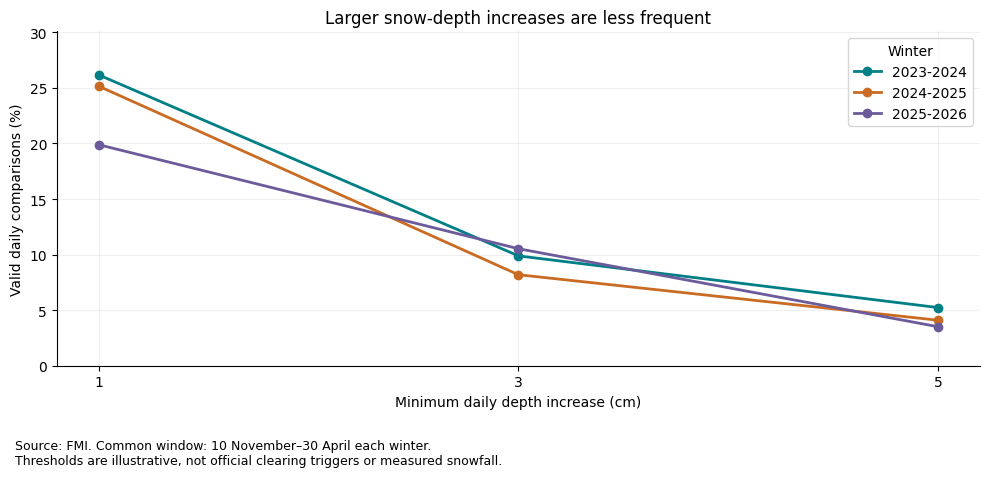

In [7]:
sensitivity_common = threshold_sensitivity(common)
sensitivity_available = threshold_sensitivity(winter)
display(sensitivity_common.round(1))
plot_sensitivity(sensitivity_common, FIGURE_DIR)

## 6. Separate event size from event frequency

Among **positive-change days only**, count changes below 3 cm, from 3 to below 5 cm, and at least 5 cm.
This different denominator answers “how large were the changes?” rather than “how often did they occur?”
The stacked bars show percentages of positive-change days; labels show the underlying counts.

A positive depth change can reflect fresh snow, wind redistribution or measurement variation. It cannot
be converted directly into a clearing visit. Settling and melting can also mask snowfall in net depth changes.

,Winter,Magnitude,Days,Positive_change_days,Share_of_positive_changes_pct
0,2023-2024,0 to <3 cm,28,45,62.2
1,2023-2024,3 to <5 cm,8,45,17.8
2,2023-2024,≥5 cm,9,45,20.0
3,2024-2025,0 to <3 cm,29,43,67.4
4,2024-2025,3 to <5 cm,7,43,16.3
5,2024-2025,≥5 cm,7,43,16.3
6,2025-2026,0 to <3 cm,16,34,47.1
7,2025-2026,3 to <5 cm,12,34,35.3
8,2025-2026,≥5 cm,6,34,17.6


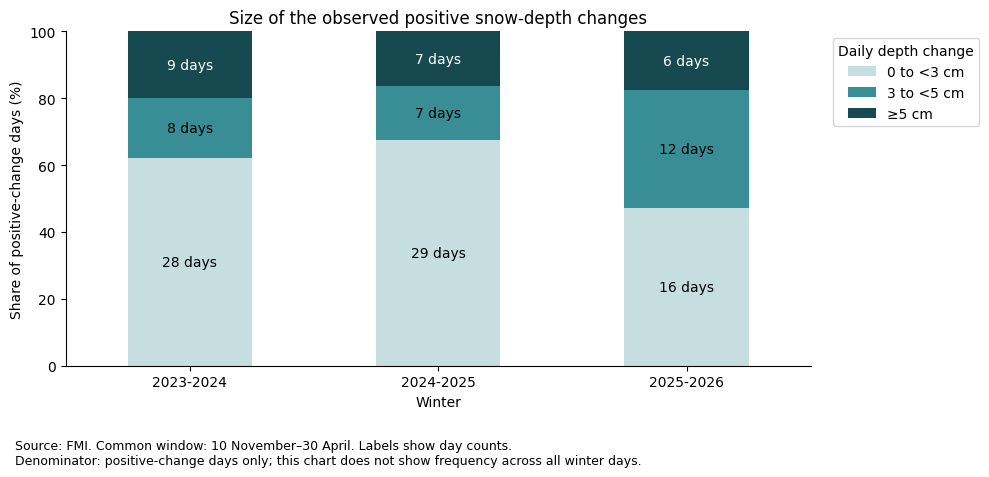

In [8]:
magnitudes = increase_magnitudes(common)
display(magnitudes.round(1))
plot_magnitudes(magnitudes, FIGURE_DIR)

**Interpretation:** The 2025–26 window has fewer positive-change days than 2024–25, but more changes of
at least 3 cm (18 versus 14). Its frequency ranking therefore changes with the threshold. The number of
small increases alone is an incomplete indicator of possible snow-clearing activity.

## 7. Export an interactive chart

The HTML chart supports hovering, choosing seasons in the legend and a date-range slider. It includes
its JavaScript for offline use. Download and open it in a browser; GitHub's file preview does not execute it.
The notebook retains static chart outputs for GitHub readers.

In [9]:
interactive = export_interactive(winter, OUTPUT_DIR)
print("Saved outputs/interactive_snow_depth.html")

Saved outputs/interactive_snow_depth.html


## 8. Check snapshot results and export reproducible tables

Synthetic edge-case tests live in `tests/test_analysis.py`. Run `python -m unittest discover -s tests -v`.
The assertions below separately confirm the results for this specific included snapshot. Investigate failures
if replacing the input; do not silently accept changed coverage or denominators.

In [10]:
assert len(raw) == 904
assert len(winter) == 597 and len(winter) >= 200
assert winter_summary["Valid_comparisons"].tolist() == [172, 211, 211]
assert winter_summary["Increase_days"].tolist() == [45, 43, 34]
assert winter_summary["Snow_covered_days"].tolist() == [170, 117, 114]
assert common_summary["Valid_snow_days"].tolist() == [173, 172, 172]
assert common_summary["Valid_comparisons"].tolist() == [172, 171, 171]
assert coverage["Expected_days"].tolist() == [213, 212, 212]
assert coverage["Absent_dates"].tolist() == [39, 0, 0]
assert coverage["Missing_snow_rows"].tolist() == [1, 0, 0]
assert winter["Snow_depth_cm"].notna().all()
assert winter["Snow_depth_cm"].eq(winter["Snow_depth_cm"].round()).all()
assert not winter["Date"].duplicated().any()

tables = {
    "Original_dataset": raw, "Winter_dataset": winter,
    "Coverage_audit": coverage, "Monthly_coverage": monthly_coverage,
    "Winter_summary": winter_summary, "Monthly_summary": monthly_summary,
    "Common_window_summary": common_summary,
    "Sensitivity_common": sensitivity_common,
    "Sensitivity_available": sensitivity_available,
    "Increase_magnitudes": magnitudes,
}
workbook_path = export_tables(tables, OUTPUT_DIR)
assert len(pd.read_excel(workbook_path, sheet_name="Winter_dataset")) == len(winter)
print("All snapshot checks passed. Saved Excel, CSV, PNG and HTML outputs.")

All snapshot checks passed. Saved Excel, CSV, PNG and HTML outputs.


## Recommendation and limits

Recurring snow-depth increases justify investigating residential snow-clearing needs. The aligned-window
and threshold analyses show that coverage and event definition materially affect the apparent opportunity.
This supports a **conditional recommendation to investigate**, rather than proof that expansion will be profitable.

The record covers one station, two complete winters and one partial winter. It cannot establish a long-term
trend, reliable forecast, unmet demand, customer willingness to pay or operational costs. Daily observations
are not independent business opportunities; no significance test treating every day as an independent season
is used. Customer research, competitor assessment and actual service records are the next evidence needed.

### Attribution and AI disclosure

- [FMI observations](https://en.ilmatieteenlaitos.fi/download-observations)
- [FMI definitions](https://www.ilmatieteenlaitos.fi/neuvoja-havaintosuureisiin)
- [FMI licence](https://en.ilmatieteenlaitos.fi/open-data-licence): CC BY 4.0. See `data/README.md` for provenance.
- AI assisted with code explanations, debugging, refactoring, tests, documentation and additional analysis.
  This is a portfolio extension, not a claim that the extensions were included in the submitted assignment.